# 02. Multilayer perceptron (MLP)

**Thesis:** Machine-Learning Prediction of Shear-Wave Velocity in the Dampier Sub-basin: Accuracy, Errors and Applications (D. Aldosaimani, Curtin University, 2026)

**What this notebook does:** Trains the MLP with the same inputs, data cleaning and LOWO validation as notebook 01, applies it to the three wells without Vs, and repeats the LOWO test with five random seeds.

**Used in:** Section 4.1; Appendix A, Table A2

**Needs:** `DATA_DIR` and `LAS_DIR` (set in the Settings cell below)

**Writes:** LOWO results table; MLP seed test

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import lasio
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Settings

In [ ]:
# ---- Settings: set these paths before running ----
DATA_DIR    = Path("../data/processed")   # the eight *_with_formation.csv files (well logs with formation names)
LAS_DIR     = Path("../data/las")         # the eight *_LQC.las files from NOPIMS (project ENO0810814A)
RESULTS_DIR = Path("../results")          # results tables are written here
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load and combine all 8 wells



In [2]:
data_dir = DATA_DIR

well_logs = {}

for csv_file in sorted(data_dir.glob("*.csv")):
    well_name = csv_file.stem
    df = pd.read_csv(csv_file)
    df.insert(0, "Well Name", well_name)
    well_logs[well_name] = df
    print(f"{well_name}: {len(df)} samples")

data_df = pd.concat(well_logs.values(), ignore_index=True)
print(f"\nLoaded {len(well_logs)} wells, {len(data_df)} total samples")

wells = data_df['Well Name'].unique()

Angel_1_with_formation: 3657 samples
Angel_3_with_formation: 15205 samples
Egret_2_with_formation: 5287 samples
Lambert_8B_with_formation: 9385 samples
Nereus_1_with_formation: 9273 samples
Persephone_1_with_formation: 9706 samples
Seraph_1_with_formation: 1470 samples
Wanaea_11A_with_formation: 3087 samples

Loaded 8 wells, 57070 total samples


In [3]:
FIGURES_DIR = Path("figures_mlp")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2b. Data cleaning (final)

Same two cleaning cells as the Regression notebook (updated_8), so every model and every result uses exactly the same rows:

1. **Remove impossible Vp:** readings faster than the fastest Vp the local minerals could have at zero porosity (Voigt bound of quartz, calcite and illite, illite given quartz properties; Mavko et al., 2009).
2. **Keep only real, unchanged measured Vs** in the 5 measured wells: `VS_ORG` exists in the LAS file and `VS_EDITED_V2` is within 2% of it.

Washouts are kept (tested in the Regression notebook), and no rule based on Vs itself is used. The 3 modelled-only wells only go through step 1.


In [4]:
# --- Remove physically impossible Vp (faster than the rock's own minerals) ---
# Upper limit at each depth = stiffest possible (Voigt) mix of its minerals at zero porosity.
# Clay (illite) is given the stiffness of quartz. Real clay is softer, so this limit is
# deliberately too high: it can only remove readings that no real rock could produce.
# Mineral properties from Mavko et al. (2009): K and mu in GPa, rho in g/cc
QUARTZ  = dict(K=37.0, mu=44.0, rho=2.65)     # solid quartz:  Vp ~ 6010 m/s
CALCITE = dict(K=76.8, mu=32.0, rho=2.71)     # solid calcite: Vp ~ 6640 m/s
REMOVE_IMPOSSIBLE_VP = True

def p_modulus(mineral):                        # P-wave modulus M = K + 4/3 mu
    return mineral['K'] + 4 / 3 * mineral['mu']

solid = data_df[['QUARTZ_COMBINER', 'CALCITE_COMBINER', 'ILLITE_COMBINER']].sum(axis=1)
f_calcite = data_df['CALCITE_COMBINER'] / solid      # calcite fraction of the solid rock
f_other = 1 - f_calcite                               # quartz + illite (both given quartz properties)

M   = f_other * p_modulus(QUARTZ) + f_calcite * p_modulus(CALCITE)      # GPa
rho = f_other * QUARTZ['rho'] + f_calcite * CALCITE['rho']               # g/cc
data_df['VP_LIMIT'] = np.sqrt(M / rho) * 1000                             # km/s -> m/s
data_df['vp_impossible'] = data_df['VP_EDITED'] > data_df['VP_LIMIT']

bad = data_df[data_df['vp_impossible']]
print(f"Depths with Vp faster than their minerals allow: {len(bad)}")
display(bad[['Well Name', 'MD', 'Formation', 'VP_EDITED', 'VP_LIMIT']].round(1))

if REMOVE_IMPOSSIBLE_VP:
    data_df = data_df[~data_df['vp_impossible']].reset_index(drop=True)
    print(f"Removed. Rows left: {len(data_df)}")


Depths with Vp faster than their minerals allow: 6


,Well Name,MD,Formation,VP_EDITED,VP_LIMIT
19480,Egret_2_with_formation,2720.5,Withnell Fm,7819.4,6289.8
19644,Egret_2_with_formation,2745.5,Withnell Fm,7181.5,6609.1
19645,Egret_2_with_formation,2745.6,Withnell Fm,7411.0,6609.6
19646,Egret_2_with_formation,2745.8,Withnell Fm,7115.9,6609.4
19749,Egret_2_with_formation,2761.5,Withnell Fm,6502.3,6437.3
53598,Seraph_1_with_formation,2977.1,Angel Fm,6146.5,6008.4


Removed. Rows left: 57064


In [5]:
# --- Keep only real measured Vs (compare VS_EDITED_V2 with VS_ORG from the LAS files) ---

MEASURED_ONLY = True   # remove depths where Vs is not a real measurement
DROP_EDITED   = True   # also remove depths where SLB changed the measured Vs by more than EDIT_TOL
EDIT_TOL      = 0.02   # 2%, same threshold as the checks in Part 3

measured_names = ['Egret_2', 'Lambert_8B', 'Nereus_1', 'Persephone_1', 'Seraph_1']
data_df['VS_ORG'] = np.nan             # modelled-only wells stay empty

for w in measured_names:
    d = lasio.read(list(LAS_DIR.rglob(f"{w}_LQC.las"))[0]).df().reset_index()
    d.columns = d.columns.str.upper()
    d = d.rename(columns={d.columns[0]: 'MD'})
    d = d[['MD', 'VS_ORG']].sort_values('MD')

    idx = data_df['Well Name'].str.contains(w)
    sub = data_df.loc[idx, ['MD']].reset_index().sort_values('MD')
    merged = pd.merge_asof(sub, d, on='MD', direction='nearest', tolerance=0.1)
    data_df.loc[merged['index'], 'VS_ORG'] = merged['VS_ORG'].values

has_org = data_df['VS_ORG'].notna()
edited = has_org & ((data_df['VS_EDITED_V2'] - data_df['VS_ORG']).abs() / data_df['VS_ORG'] > EDIT_TOL)
data_df['VS_MEASURED'] = (has_org & ~edited) if DROP_EDITED else has_org

# Summary per measured well
in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
names = data_df.loc[in_measured_well, 'Well Name']
summary = pd.DataFrame({
    'rows': names.value_counts().sort_index(),
    '% real, unchanged': (100 * (has_org & ~edited)[in_measured_well].groupby(names).mean()).round(1),
    '% real, edited by SLB': (100 * edited[in_measured_well].groupby(names).mean()).round(1),
    '% modelled (no VS_ORG)': (100 * (~has_org)[in_measured_well].groupby(names).mean()).round(1),
})
print(summary)

if MEASURED_ONLY:
    data_df = data_df[~in_measured_well | data_df['VS_MEASURED']].reset_index(drop=True)
    print("\nRows kept per well:")
    print(data_df.groupby('Well Name').size())

    # Check: every row left in the 5 measured wells is a real measurement
    in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
    assert data_df.loc[in_measured_well, 'VS_MEASURED'].all()
    print("\nCheck passed: all rows left in the 5 measured wells are real measured Vs")


                             rows  % real, unchanged  % real, edited by SLB  \
Well Name                                                                     
Egret_2_with_formation       5282               85.3                   14.1   
Lambert_8B_with_formation    9385              100.0                    0.0   
Nereus_1_with_formation      9273               96.5                    2.9   
Persephone_1_with_formation  9706               32.2                    1.0   
Seraph_1_with_formation      1469               53.3                    2.2   

                             % modelled (no VS_ORG)  
Well Name                                            
Egret_2_with_formation                          0.6  
Lambert_8B_with_formation                       0.0  
Nereus_1_with_formation                         0.6  
Persephone_1_with_formation                    66.8  
Seraph_1_with_formation                        44.5  

Rows kept per well:
Well Name
Angel_1_with_formation          3657


## 3. Define well groups (measured vs modelled-only)

This split controls which wells are allowed into LOWO training and testing (Section 5) — not just how results get reported at the end.

In [6]:
measured_wells = [
    'Egret_2_with_formation',
    'Lambert_8B_with_formation',
    'Nereus_1_with_formation',
    'Persephone_1_with_formation',
    'Seraph_1_with_formation',
]

modelled_wells = [
    'Angel_1_with_formation',
    'Angel_3_with_formation',
    'Wanaea_11A_with_formation',
]

print("Measured wells (used for LOWO validation):", len(measured_wells))
print("Modelled-only wells (used later in Part 2 only):", len(modelled_wells))

Measured wells (used for LOWO validation): 5
Modelled-only wells (used later in Part 2 only): 3


## 4. Define features and target

5 features. Two changes from the earlier 6-feature set, per Olivia's feedback:

- Resistivity is fed in as `RESD_LOG` (log10 of RESD_EDITED), not the raw ohm-m values. Resistivity is a log-normally distributed quantity, so a log10 transform is standard practice before feeding it into a model.
- `VCL_GEO_QEPP` (clay volume) has been dropped — it's derived from GR_EDITED, so keeping both as separate model inputs double-counts the same information.

In [7]:
data_df['RESD_LOG'] = np.log10(data_df['RESD_EDITED'])

features_reg = [
    'GR_EDITED',
    'RHOB_EDITED',
    'NPHI_EDITED',
    'RESD_LOG',
    'VP_EDITED',
]

target_reg = 'VS_EDITED_V2'

missing = data_df[features_reg + [target_reg]].isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values in features/target")

No missing values in features/target


## 5. MLP Regression — LOWO cross-validation (5 measured wells)

Same fold structure as the linear-family notebook: hold out one measured well, train on the other 4, test on the held-out one, repeat 5 times. The 3 modelled-only wells are excluded from training entirely, same as before.

A few things are different for a neural network compared to Linear/Ridge/Lasso, worth knowing:

- **Scaling is required, not optional.** MLPs are much more sensitive to feature scale than linear models — without scaling, a feature like VP (thousands) would dominate the network's early training over NPHI (0-0.4) regardless of which one actually matters more. The scaler is fit on the 4 training wells only, same rule as before.
- **Architecture is a choice, not something the data tells you.** `hidden_layer_sizes=(32, 16)` means two hidden layers, 32 neurons then 16 — a small network, chosen deliberately given you only have ~4 wells and a few thousand rows of training data per fold. A bigger network would have more capacity to memorize noise (overfit) rather than learn a genuine pattern, which is a real risk with this little data.
- **`random_state=42` is set for reproducibility.** Unlike Linear/Ridge/Lasso, an MLP's starting weights are randomized, so without fixing this, re-running the same cell would give slightly different results each time.
- **`early_stopping=True`** holds out a small slice of the training data internally and stops training once performance on that slice stops improving — a standard way to avoid overfitting without having to hand-pick the number of training iterations.

In [8]:
results = []

for val_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        max_iter=2000,
        early_stopping=True,
        random_state=42
    )
    model.fit(X_train, train_df[target_reg])

    pred = model.predict(X_val)

    r2 = r2_score(val_df[target_reg], pred)
    rmse = np.sqrt(mean_squared_error(val_df[target_reg], pred))
    mae = mean_absolute_error(val_df[target_reg], pred)

    results.append({
        'Validation Well': val_well,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae
    })

results_mlp = pd.DataFrame(results)
results_mlp['Model'] = 'MLP Regression'
results_mlp = results_mlp[['Model', 'Validation Well', 'R2', 'RMSE', 'MAE']]
results_mlp.to_csv(RESULTS_DIR / 'lowo_mlp_regression.csv', index=False)

print("Mean R2:", results_mlp['R2'].mean())
print("Mean RMSE:", results_mlp['RMSE'].mean())
print("Mean MAE:", results_mlp['MAE'].mean())

results_mlp

Mean R2: 0.5317126459653909
Mean RMSE: 212.66754412101545
Mean MAE: 166.86667925611653


,Model,Validation Well,R2,RMSE,MAE
0,MLP Regression,Egret_2_with_formation,0.773866,180.983365,127.290159
1,MLP Regression,Lambert_8B_with_formation,0.775575,141.248821,104.722845
2,MLP Regression,Nereus_1_with_formation,0.780364,208.217484,162.633225
3,MLP Regression,Persephone_1_with_formation,-0.605853,384.765780,330.724917
4,MLP Regression,Seraph_1_with_formation,0.934611,148.122270,108.962251


### Diagnostic plot — actual vs predicted Vs, for every measured well

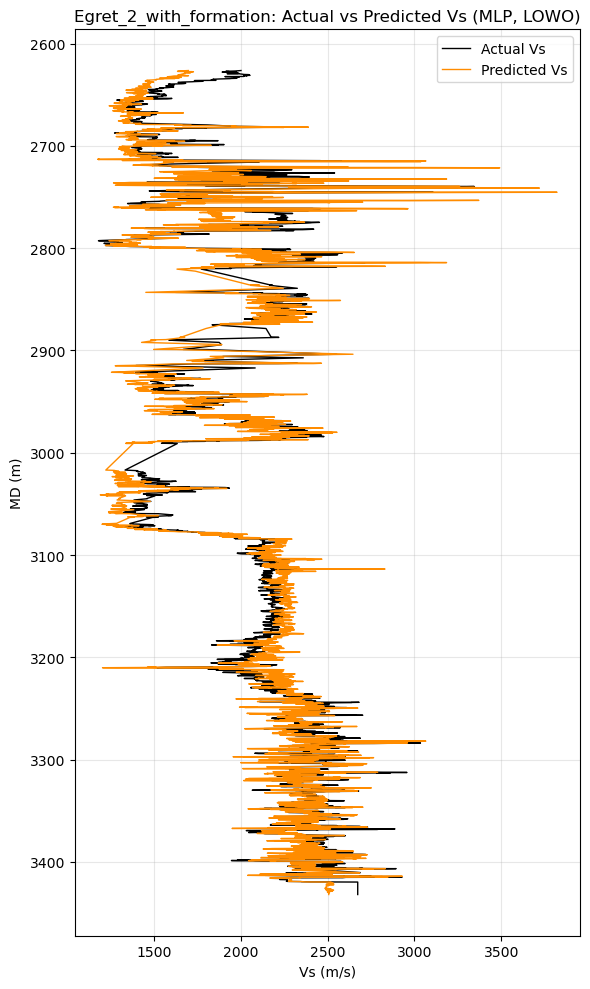

Egret_2_with_formation  R²=0.774  RMSE=181.0 m/s


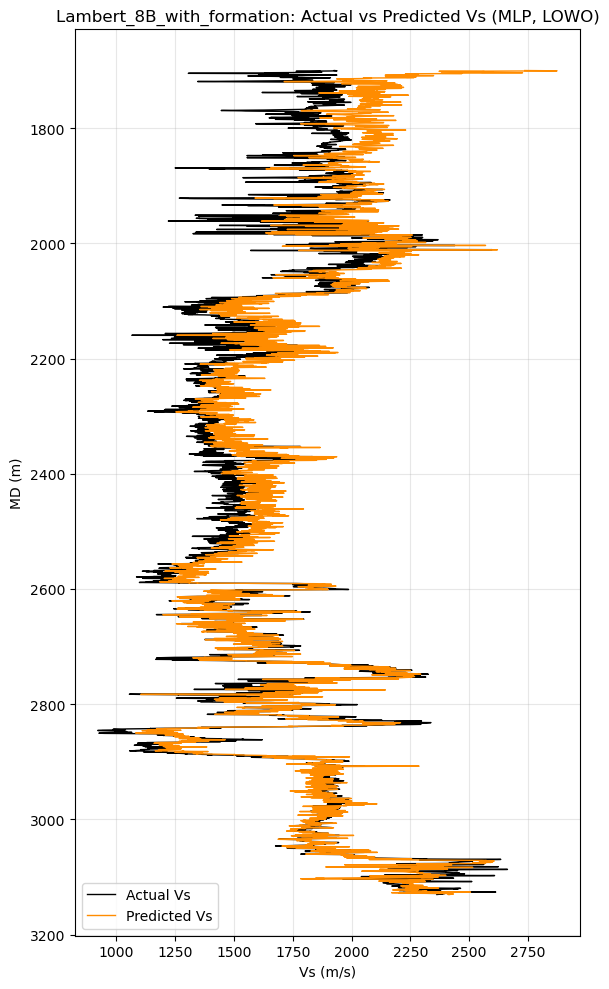

Lambert_8B_with_formation  R²=0.776  RMSE=141.2 m/s


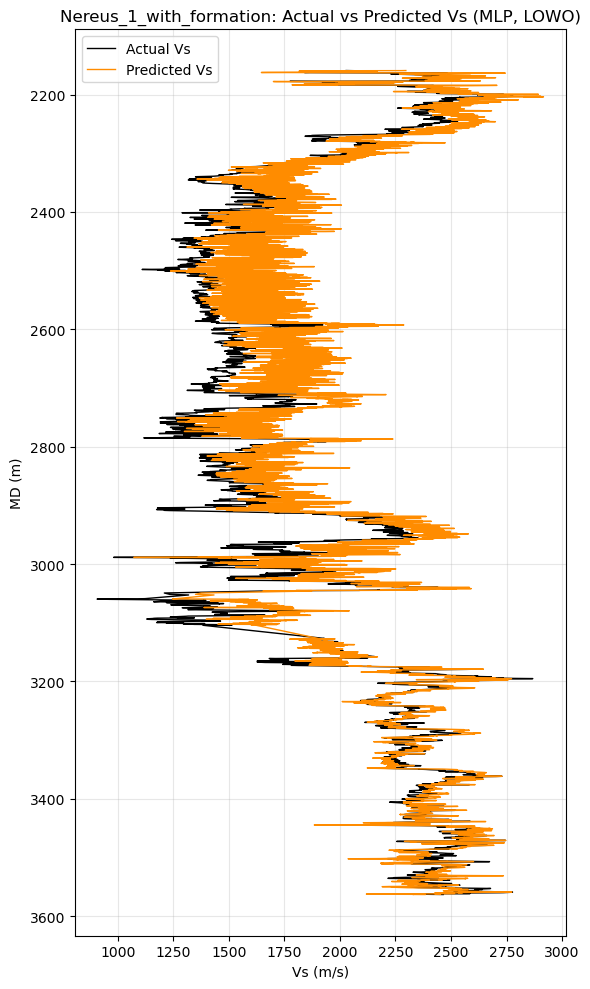

Nereus_1_with_formation  R²=0.780  RMSE=208.2 m/s


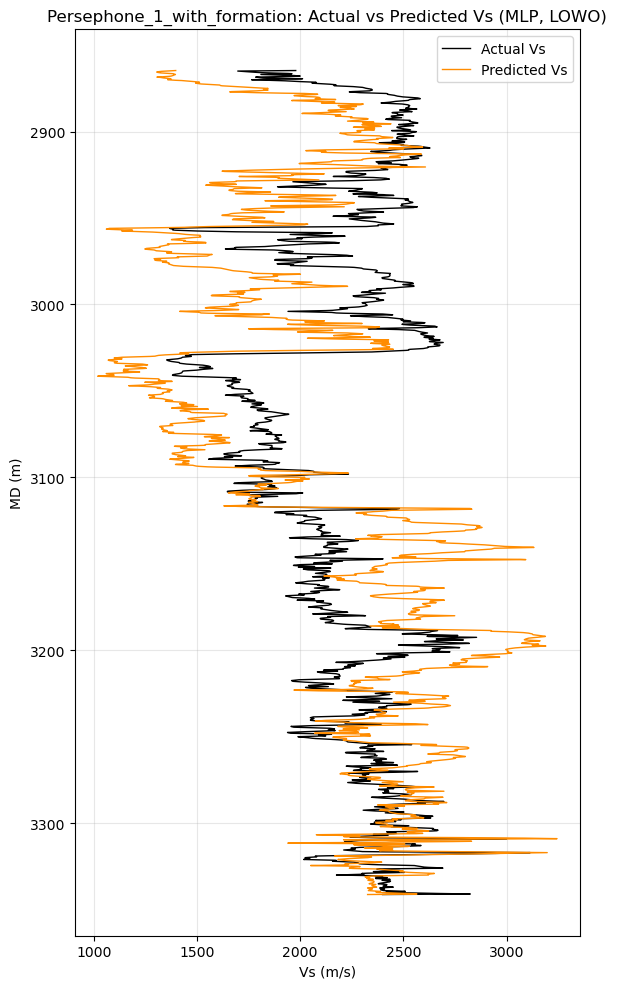

Persephone_1_with_formation  R²=-0.606  RMSE=384.8 m/s


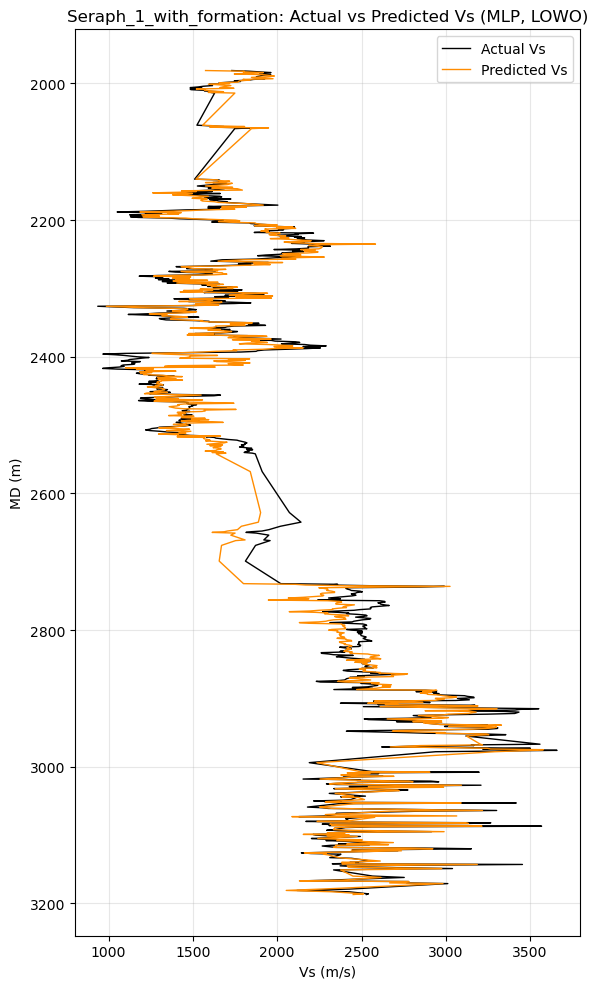

Seraph_1_with_formation  R²=0.935  RMSE=148.1 m/s


In [9]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        max_iter=2000,
        early_stopping=True,
        random_state=42
    )
    model.fit(X_train, train_df[target_reg])

    val_df['VS_PRED'] = model.predict(X_val)

    plt.figure(figsize=(6, 10))
    plt.plot(val_df[target_reg], val_df['MD'], label='Actual Vs', color='black', lw=1)
    plt.plot(val_df['VS_PRED'], val_df['MD'], label='Predicted Vs', color='darkorange', lw=1)
    plt.gca().invert_yaxis()
    plt.xlabel('Vs (m/s)')
    plt.ylabel('MD (m)')
    plt.title(f'{plot_well}: Actual vs Predicted Vs (MLP, LOWO)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"mlp_actual_vs_predicted_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

    r2 = r2_score(val_df[target_reg], val_df['VS_PRED'])
    rmse = np.sqrt(mean_squared_error(val_df[target_reg], val_df['VS_PRED']))
    print(f"{plot_well}  R²={r2:.3f}  RMSE={rmse:.1f} m/s")

### Diagnostic plot — multi-track well log display, for every measured well

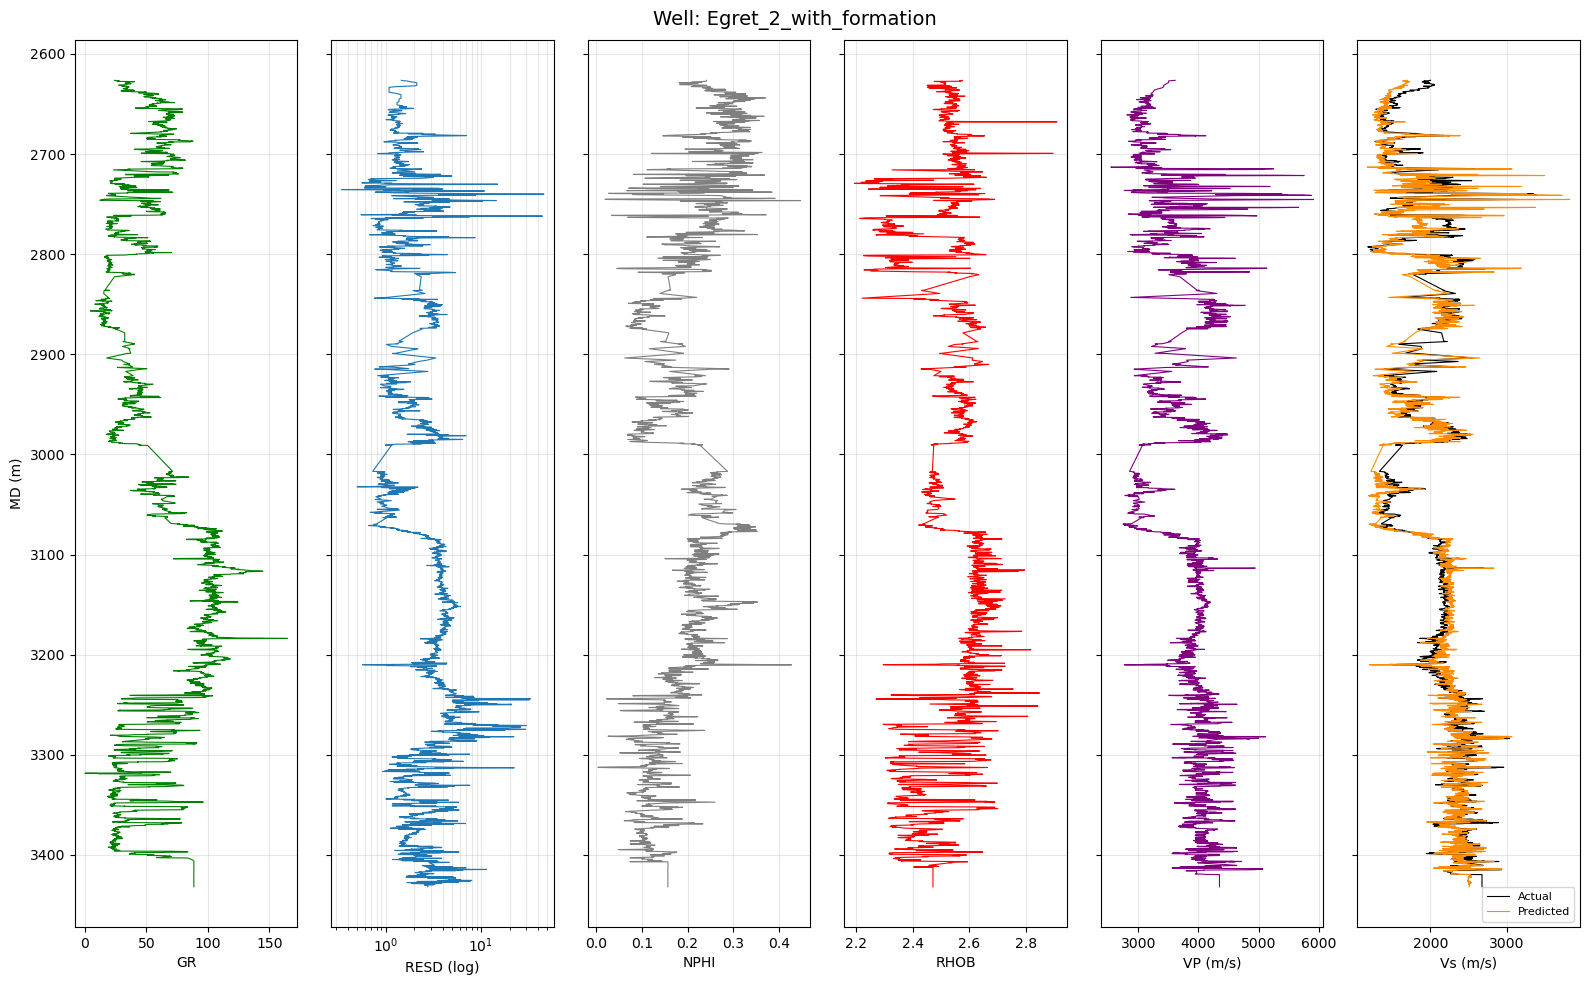

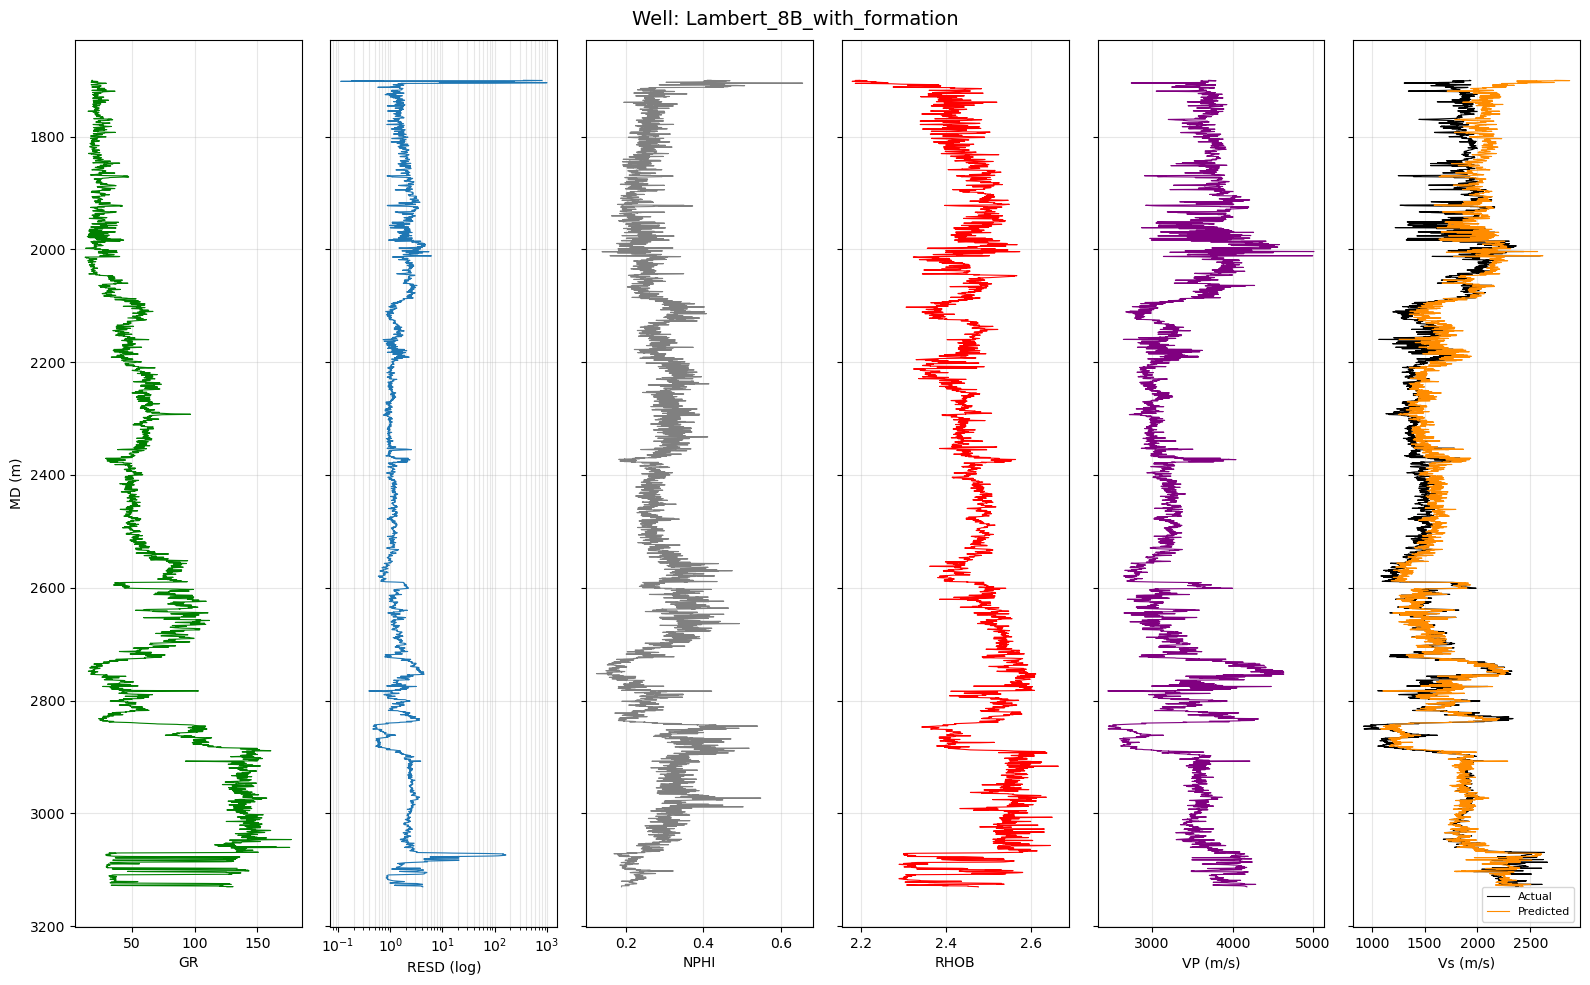

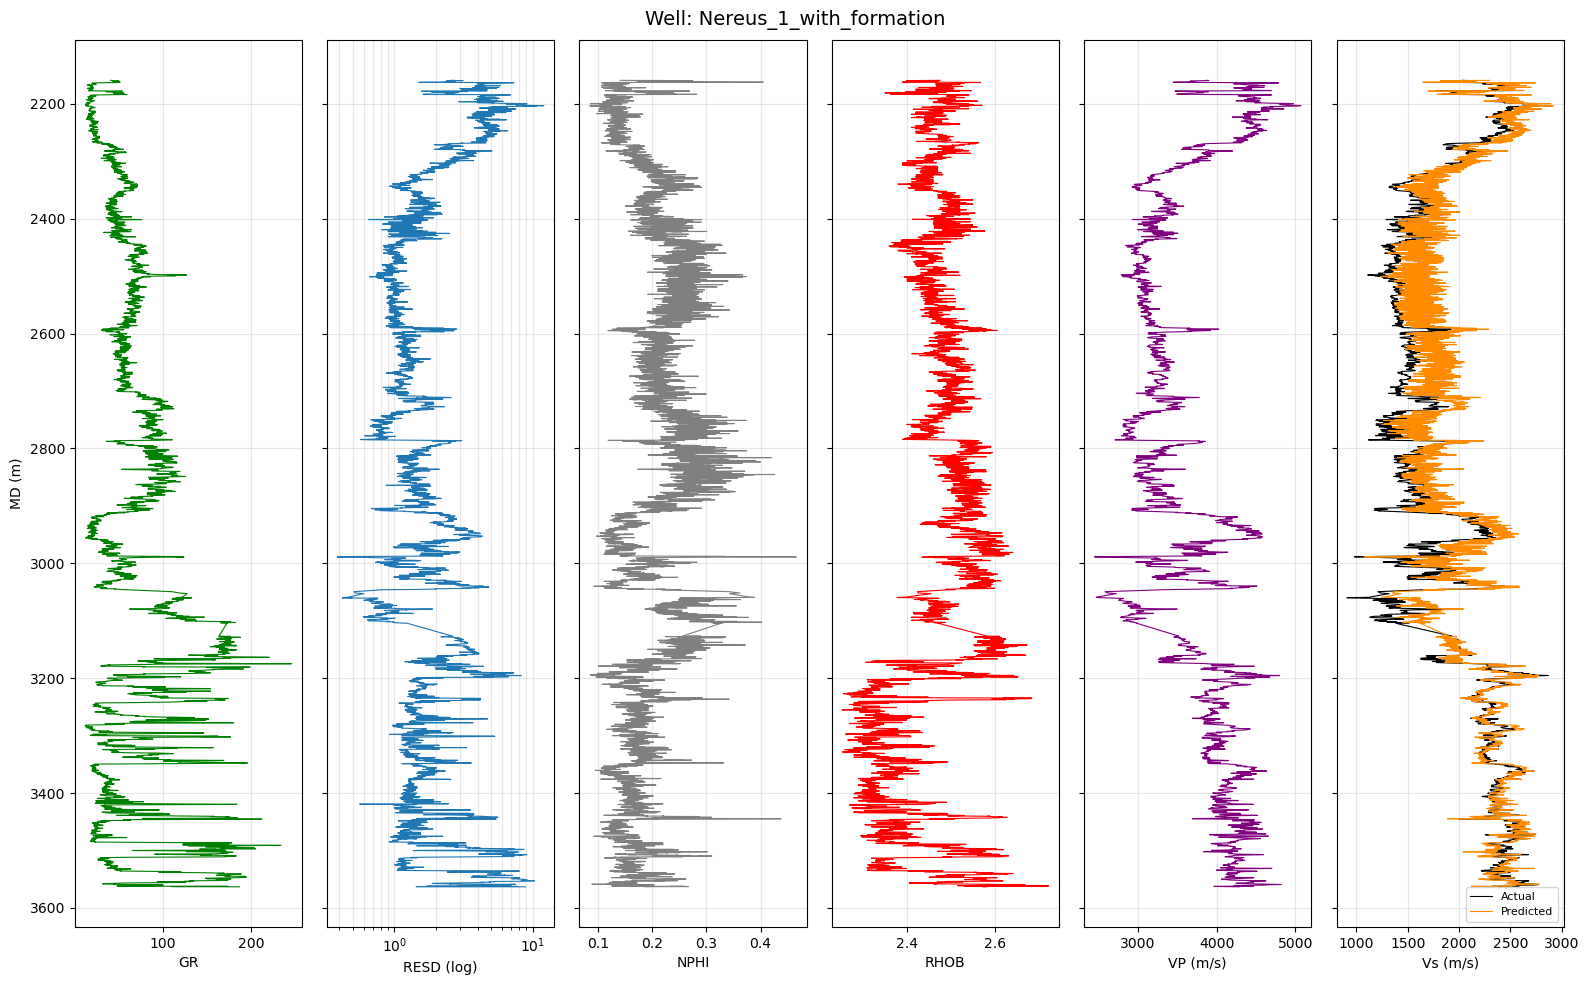

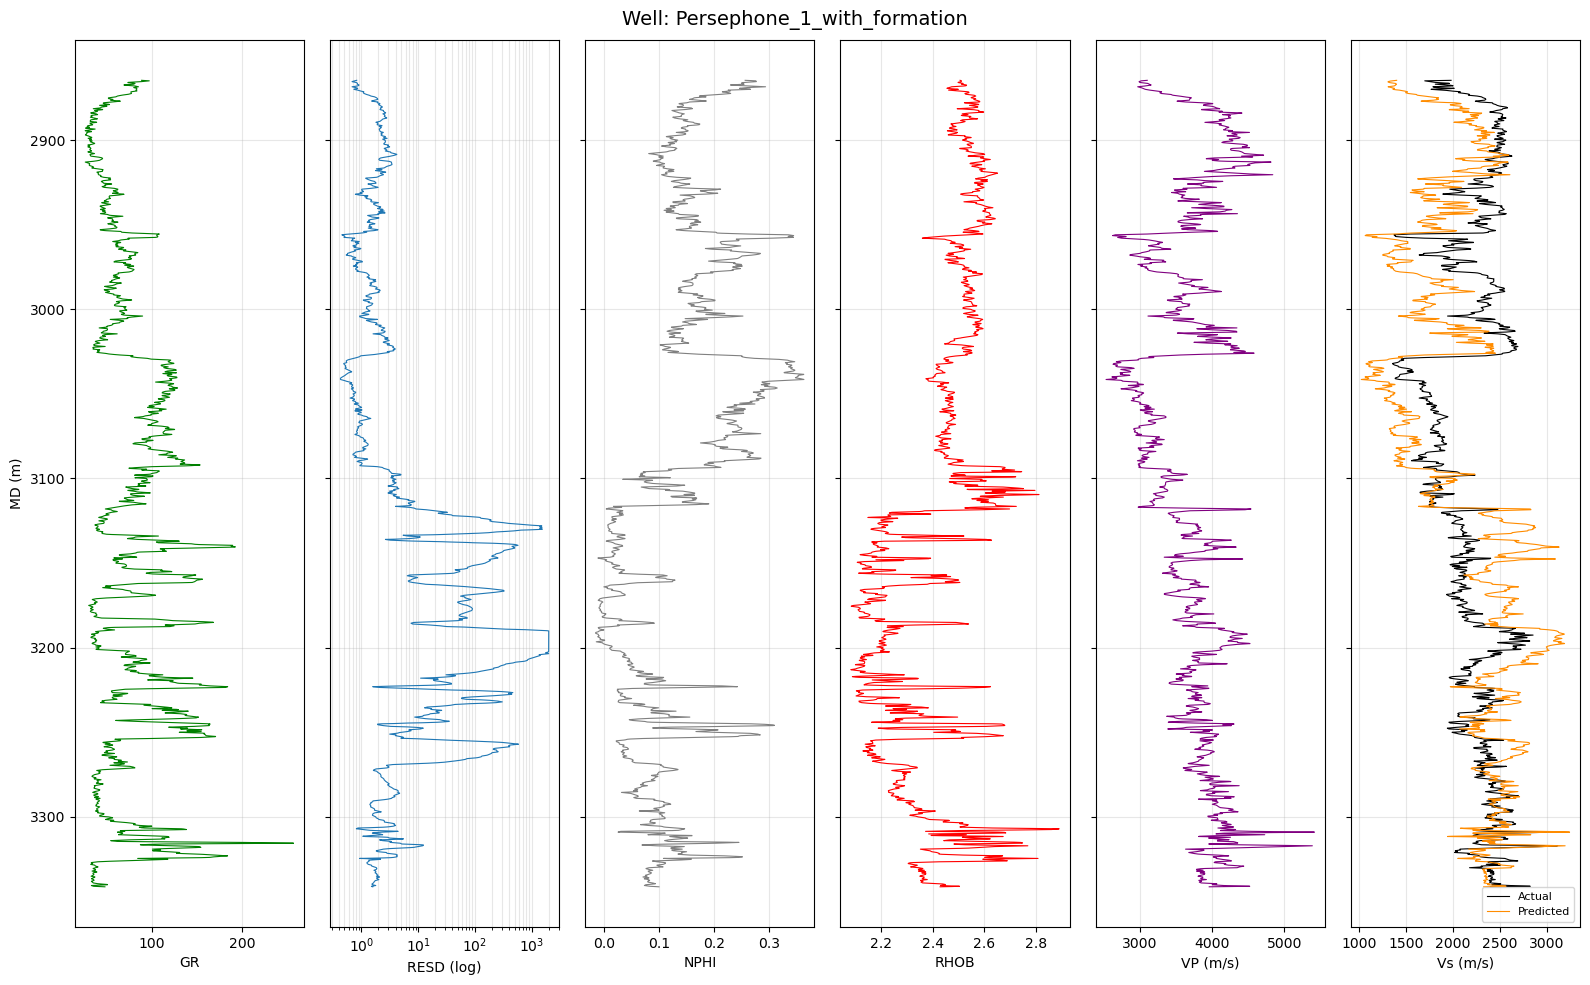

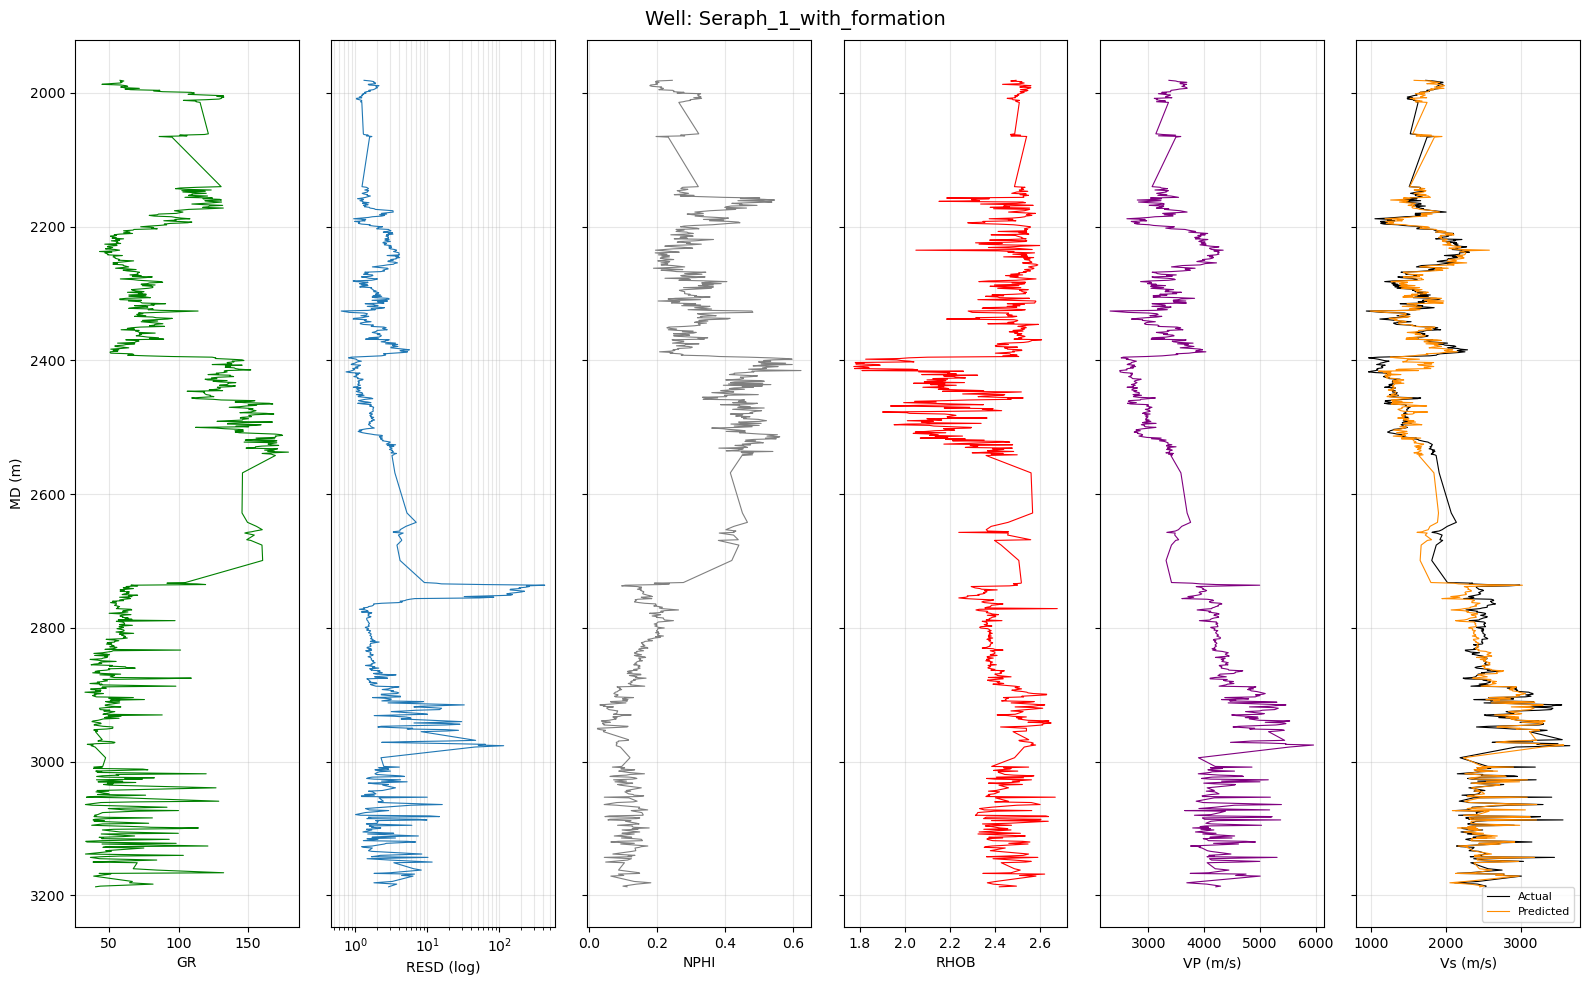

In [10]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        max_iter=2000,
        early_stopping=True,
        random_state=42
    )
    model.fit(X_train, train_df[target_reg])
    val_df['VS_PRED'] = model.predict(X_val)

    depth = val_df['MD']

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(16, 10), sharey=True)

    # Track 1 - GR
    axes[0].plot(val_df['GR_EDITED'], depth, color='green', lw=0.8)
    axes[0].set_xlabel('GR')
    axes[0].grid(alpha=0.3)

    # Track 2 - Resistivity (log scale is standard convention for resistivity)
    axes[1].plot(val_df['RESD_EDITED'], depth, color='tab:blue', lw=0.8)
    axes[1].set_xscale('log')
    axes[1].set_xlabel('RESD (log)')
    axes[1].grid(alpha=0.3, which='both')

    # Track 3 - NPHI (neutron porosity)
    axes[2].plot(val_df['NPHI_EDITED'], depth, color='gray', lw=0.8)
    axes[2].set_xlabel('NPHI')
    axes[2].grid(alpha=0.3)

    # Track 4 - RHOB (density)
    axes[3].plot(val_df['RHOB_EDITED'], depth, color='red', lw=0.8)
    axes[3].set_xlabel('RHOB')
    axes[3].grid(alpha=0.3)

    # Track 5 - VP (compressional velocity, strongest predictor)
    axes[4].plot(val_df['VP_EDITED'], depth, color='purple', lw=0.8)
    axes[4].set_xlabel('VP (m/s)')
    axes[4].grid(alpha=0.3)

    # Track 6 - Actual vs Predicted Vs
    axes[5].plot(val_df[target_reg], depth, color='black', lw=0.8, label='Actual')
    axes[5].plot(val_df['VS_PRED'], depth, color='darkorange', lw=0.8, label='Predicted')
    axes[5].set_xlabel('Vs (m/s)')
    axes[5].legend(fontsize=8, loc='lower right')
    axes[5].grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel('MD (m)')
    fig.suptitle(f'Well: {plot_well}', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"mlp_multitrack_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()



### Residual diagnostics (MLP Regression, pooled across 5 wells)

Residual (predicted minus actual) plotted against actual Vs and against depth -- checks for bias that a single averaged R²/RMSE can hide, e.g. systematic under/over-prediction at particular Vs ranges or depths.

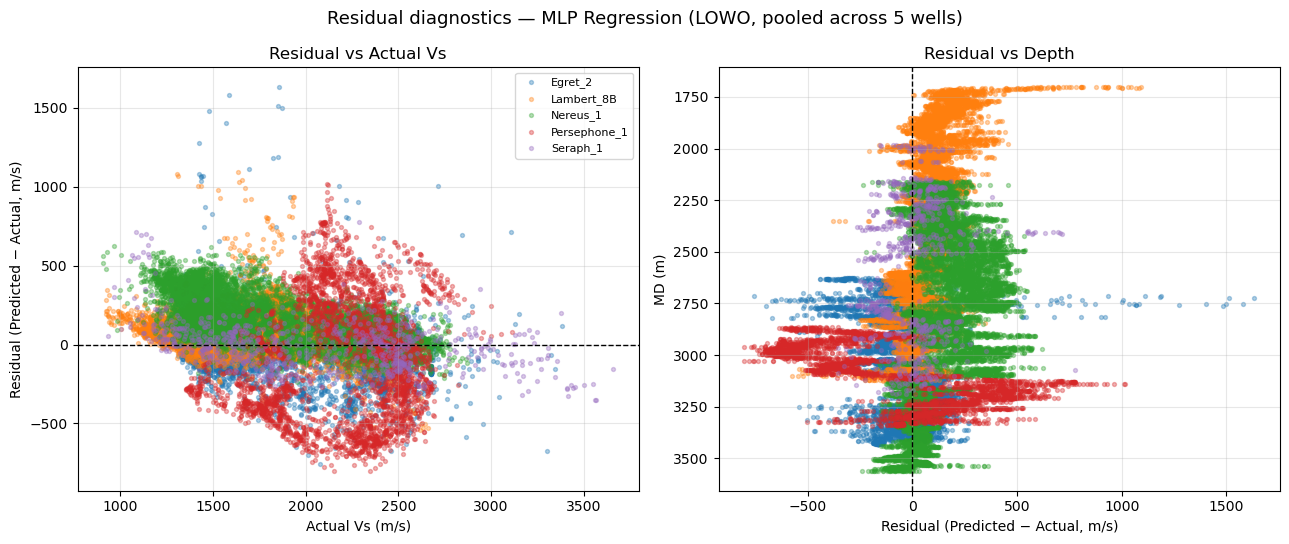

Mean residual: 60.37 m/s   Std residual: 203.30 m/s


In [11]:
actual_all, predicted_all, depth_all, well_all = [], [], [], []

for val_well in measured_wells:
    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    model = MLPRegressor(
        hidden_layer_sizes=(32, 16), activation='relu', solver='adam',
        max_iter=2000, early_stopping=True, random_state=42
    )
    model.fit(X_train, train_df[target_reg])
    pred = model.predict(X_val)

    actual_all.extend(val_df[target_reg].values)
    predicted_all.extend(pred)
    depth_all.extend(val_df['MD'].values)
    well_all.extend([val_well.replace('_with_formation', '')] * len(val_df))

resid_df = pd.DataFrame({'Actual': actual_all, 'Predicted': predicted_all, 'Depth': depth_all, 'Well': well_all})
resid_df['Residual'] = resid_df['Predicted'] - resid_df['Actual']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for well_name, group in resid_df.groupby('Well'):
    axes[0].scatter(group['Actual'], group['Residual'], s=8, alpha=0.35, label=well_name)
axes[0].axhline(0, color='black', lw=1, ls='--')
axes[0].set_xlabel('Actual Vs (m/s)')
axes[0].set_ylabel('Residual (Predicted − Actual, m/s)')
axes[0].set_title('Residual vs Actual Vs')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for well_name, group in resid_df.groupby('Well'):
    axes[1].scatter(group['Residual'], group['Depth'], s=8, alpha=0.35, label=well_name)
axes[1].axvline(0, color='black', lw=1, ls='--')
axes[1].invert_yaxis()
axes[1].set_xlabel('Residual (Predicted − Actual, m/s)')
axes[1].set_ylabel('MD (m)')
axes[1].set_title('Residual vs Depth')
axes[1].grid(alpha=0.3)

fig.suptitle('Residual diagnostics — MLP Regression (LOWO, pooled across 5 wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mlp_residual_diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean residual: {resid_df['Residual'].mean():.2f} m/s   Std residual: {resid_df['Residual'].std():.2f} m/s")


## 6. Build training/prediction sets

In [12]:
train_df = data_df[data_df['Well Name'].isin(measured_wells)]
predict_df = data_df[data_df['Well Name'].isin(modelled_wells)].copy()

print("Training samples (5 measured wells):", len(train_df))
print("Samples to predict (3 modelled-only wells):", len(predict_df))

Training samples (5 measured wells): 26749
Samples to predict (3 modelled-only wells): 21949


## 7. MLP Regression — train on measured, predict modelled-only

In [13]:
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(train_df[features_reg])
X_predict_scaled = scaler_final.transform(predict_df[features_reg])

model_final_mlp = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=2000,
    early_stopping=True,
    random_state=42
)
model_final_mlp.fit(X_train_scaled, train_df[target_reg])

predict_df['VS_PRED_MLP'] = model_final_mlp.predict(X_predict_scaled)

### MLP training loss curve

Training loss per iteration for the final MLP (trained on all 5 measured wells) -- checks that the network actually converged rather than being cut off early or undertrained, which would help explain why MLP is the weakest model in the comparison.

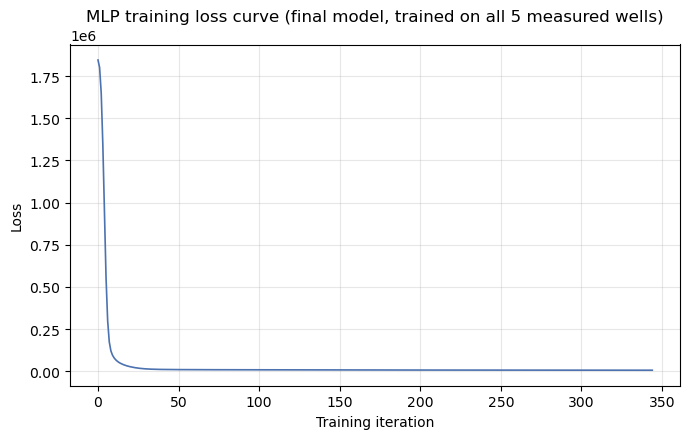

Final training loss: 5666.1779  (345 iterations)


In [14]:
plt.figure(figsize=(7, 4.5))
plt.plot(model_final_mlp.loss_curve_, color='#4C72B0', lw=1.2)
plt.xlabel('Training iteration')
plt.ylabel('Loss')
plt.title('MLP training loss curve (final model, trained on all 5 measured wells)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mlp_loss_curve.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Final training loss: {model_final_mlp.loss_curve_[-1]:.4f}  ({len(model_final_mlp.loss_curve_)} iterations)")


In [15]:
results = []

for well in modelled_wells:
    well_df = predict_df[predict_df['Well Name'] == well]

    results.append({
        'Well': well,
        'R2 vs SLB estimate': r2_score(well_df[target_reg], well_df['VS_PRED_MLP']),
        'RMSE vs SLB estimate': np.sqrt(mean_squared_error(well_df[target_reg], well_df['VS_PRED_MLP'])),
        'MAE vs SLB estimate': mean_absolute_error(well_df[target_reg], well_df['VS_PRED_MLP'])
    })

results_vs_slb_vs_pred_mlp = pd.DataFrame(results)
results_vs_slb_vs_pred_mlp

,Well,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
0,Angel_1_with_formation,0.789000,202.032523,148.278952
1,Angel_3_with_formation,0.814676,198.650650,131.678011
2,Wanaea_11A_with_formation,0.937326,68.904094,45.183244


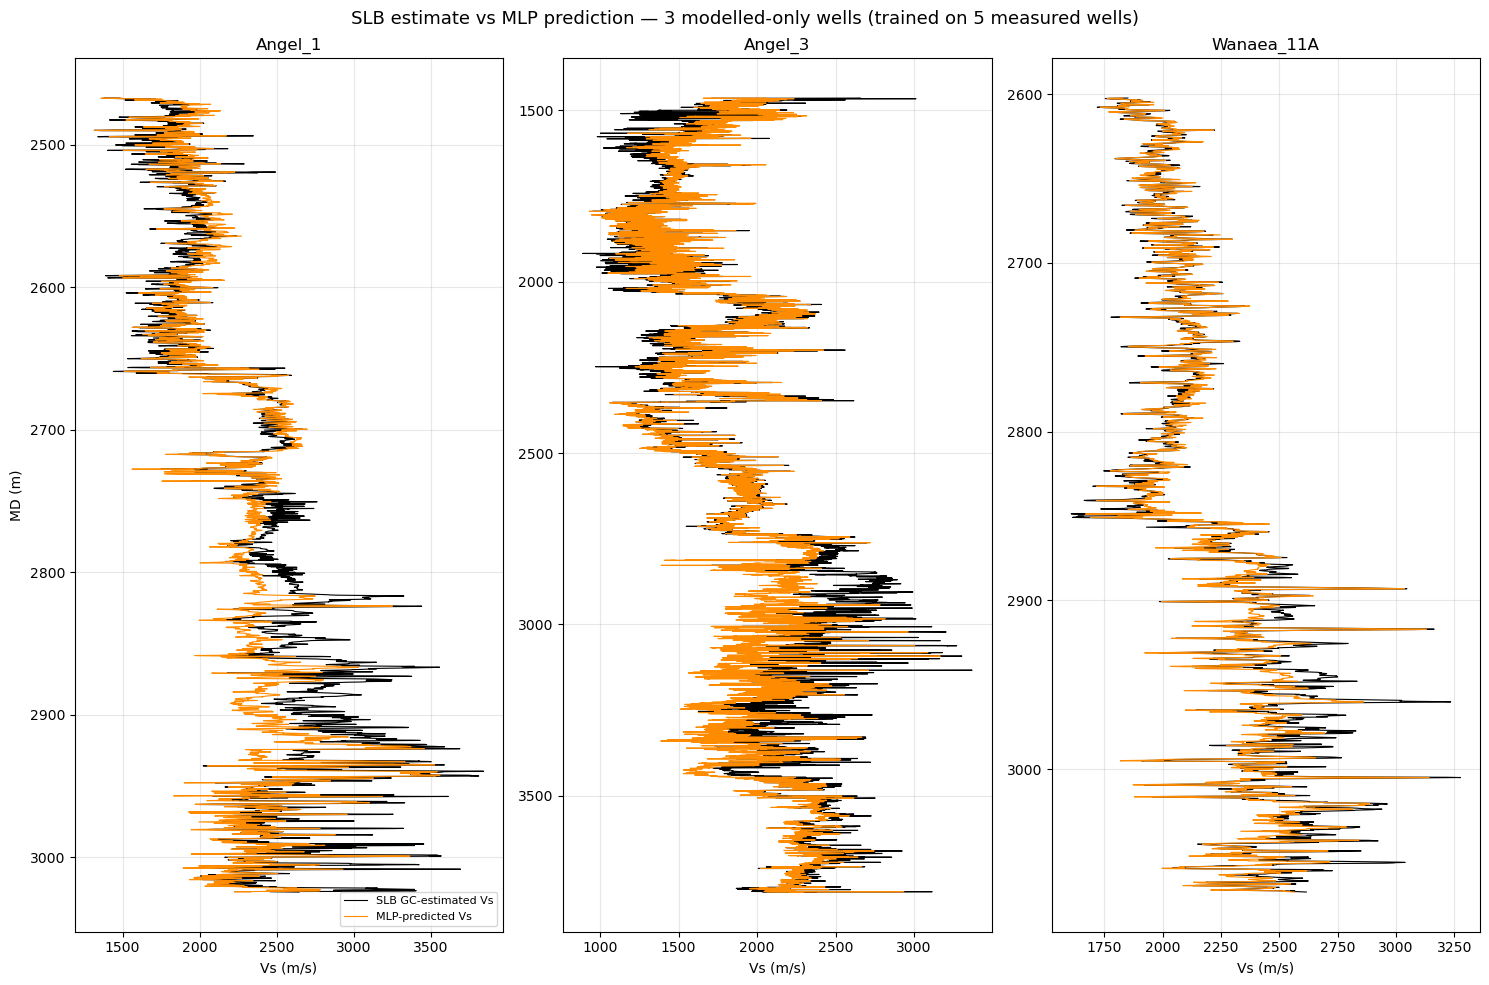

In [16]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

for ax, well in zip(axes, modelled_wells):
    well_df = predict_df[predict_df['Well Name'] == well]

    ax.plot(well_df[target_reg], well_df['MD'], color='black', lw=0.8, label='SLB GC-estimated Vs')
    ax.plot(well_df['VS_PRED_MLP'], well_df['MD'], color='darkorange', lw=0.8, label='MLP-predicted Vs')
    ax.invert_yaxis()
    ax.set_xlabel('Vs (m/s)')
    ax.set_title(well.replace('_with_formation', ''))
    ax.grid(alpha=0.3)

axes[0].set_ylabel('MD (m)')
axes[0].legend(fontsize=8, loc='lower right')

fig.suptitle('SLB estimate vs MLP prediction — 3 modelled-only wells (trained on 5 measured wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mlp_part2_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

MLP LOWO results across 5 random seeds, per well (std_RMSE large relative to mean_RMSE = unstable fold)


,mean_R2,std_R2,mean_RMSE,std_RMSE,min_RMSE,max_RMSE
Validation Well,,,,,,
Egret_2,0.779,0.016,178.934,6.687,169.200,187.452
Lambert_8B,0.789,0.035,136.527,11.709,118.450,148.182
Nereus_1,0.805,0.044,195.042,22.289,170.600,220.094
Persephone_1,-0.589,0.227,382.030,26.833,352.979,423.600
Seraph_1,0.898,0.030,183.523,27.776,148.122,213.295


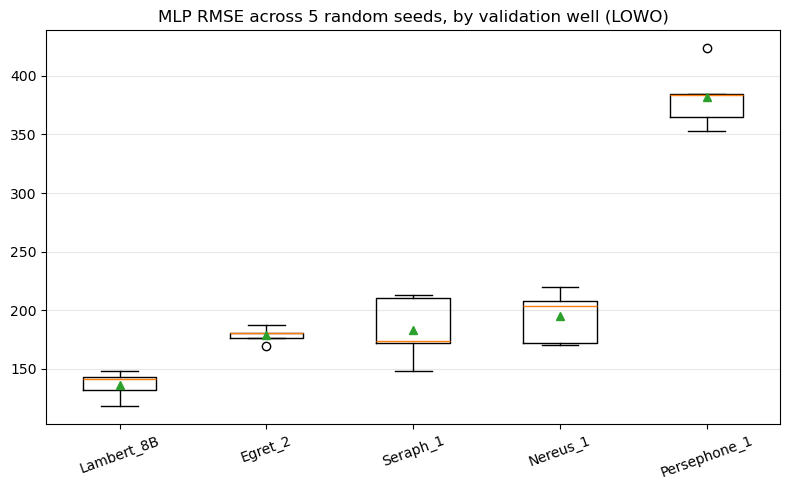

In [17]:
# --- MLP stability check: does the LOWO result depend on the random seed? ---
SEEDS = [0, 1, 42, 123, 2024]   # 42 is the seed already used elsewhere in this notebook

seed_results = []
for seed in SEEDS:
    for val_well in measured_wells:
        train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
        val_df = data_df[data_df['Well Name'] == val_well]

        scaler = StandardScaler()
        X_train = scaler.fit_transform(train_df[features_reg])
        X_val = scaler.transform(val_df[features_reg])

        model = MLPRegressor(
            hidden_layer_sizes=(32, 16), activation='relu', solver='adam',
            max_iter=2000, early_stopping=True, random_state=seed
        )
        model.fit(X_train, train_df[target_reg])
        pred = model.predict(X_val)

        seed_results.append({
            'Seed': seed,
            'Validation Well': val_well.replace('_with_formation', ''),
            'R2': r2_score(val_df[target_reg], pred),
            'RMSE': np.sqrt(mean_squared_error(val_df[target_reg], pred)),
        })

seed_df = pd.DataFrame(seed_results)
seed_df.to_csv(RESULTS_DIR / 'mlp_seed_stability.csv', index=False)

# Summary: mean +/- std across seeds, per well
stability = seed_df.groupby('Validation Well').agg(
    mean_R2=('R2', 'mean'), std_R2=('R2', 'std'),
    mean_RMSE=('RMSE', 'mean'), std_RMSE=('RMSE', 'std'),
    min_RMSE=('RMSE', 'min'), max_RMSE=('RMSE', 'max'),
).round(3)
print(f"MLP LOWO results across {len(SEEDS)} random seeds, per well "
      f"(std_RMSE large relative to mean_RMSE = unstable fold)")
display(stability)

# Figure: RMSE spread per well across seeds
fig, ax = plt.subplots(figsize=(8, 5))
wells_order = stability.sort_values('mean_RMSE').index
box_data = [seed_df[seed_df['Validation Well'] == w]['RMSE'].values for w in wells_order]
ax.boxplot(box_data, tick_labels=list(wells_order), showmeans=True)
ax.set_title(f'MLP RMSE across {len(SEEDS)} random seeds, by validation well (LOWO)')
ax.grid(alpha=0.3, axis='y')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mlp_seed_stability.png', dpi=300, bbox_inches='tight')
plt.show()